In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/student_performance.csv')

display(df.head())


,Hours Studied,Attendance (%),Previous Score,Assignment_Completion(%),Final Score
0,2,70,55,87,58
1,4,80,65,83,70
2,6,90,75,49,84
3,3,75,60,50,64
4,8,95,85,29,92


In [2]:

print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Hours Studied             5 non-null      int64
 1   Attendance (%)            5 non-null      int64
 2   Previous Score            5 non-null      int64
 3   Assignment_Completion(%)  5 non-null      int64
 4    Final Score              5 non-null      int64
dtypes: int64(5)
memory usage: 328.0 bytes
None


In [7]:

print("Missing values:\n", df.isnull().sum())

Missing values:
 Hours Studied               0
Attendance (%)              0
Previous Score              0
Assignment_Completion(%)    0
 Final Score                0
dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [9]:
display(df.describe())

,Hours Studied,Attendance (%),Previous Score,Assignment_Completion(%),Final Score
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,4.600000,82.000000,68.000000,59.600000,73.600000
std,2.408319,10.368221,12.041595,24.694129,14.099645
min,2.000000,70.000000,55.000000,29.000000,58.000000
25%,3.000000,75.000000,60.000000,49.000000,64.000000
50%,4.000000,80.000000,65.000000,50.000000,70.000000
75%,6.000000,90.000000,75.000000,83.000000,84.000000
max,8.000000,95.000000,85.000000,87.000000,92.000000


In [10]:
# Correlation matrix
print(df.corr())

                          Hours Studied  Attendance (%)  Previous Score  \
Hours Studied                  1.000000        0.991190        1.000000   
Attendance (%)                 0.991190        1.000000        0.991190   
Previous Score                 1.000000        0.991190        1.000000   
Assignment_Completion(%)      -0.793660       -0.772358       -0.793660   
 Final Score                   0.995393        0.998712        0.995393   

                          Assignment_Completion(%)   Final Score  
Hours Studied                            -0.793660      0.995393  
Attendance (%)                           -0.772358      0.998712  
Previous Score                           -0.793660      0.995393  
Assignment_Completion(%)                  1.000000     -0.784655  
 Final Score                             -0.784655      1.000000  


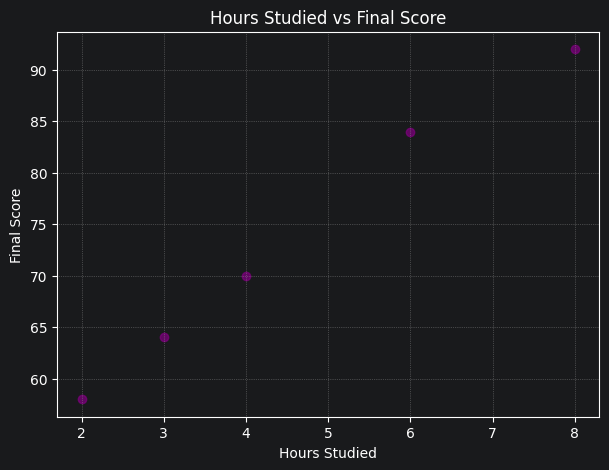

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df['Hours Studied'], df.iloc[:, -1], color='purple', alpha=0.7)
plt.xlabel('Hours Studied')
plt.ylabel('Final Score')
plt.title('Hours Studied vs Final Score')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

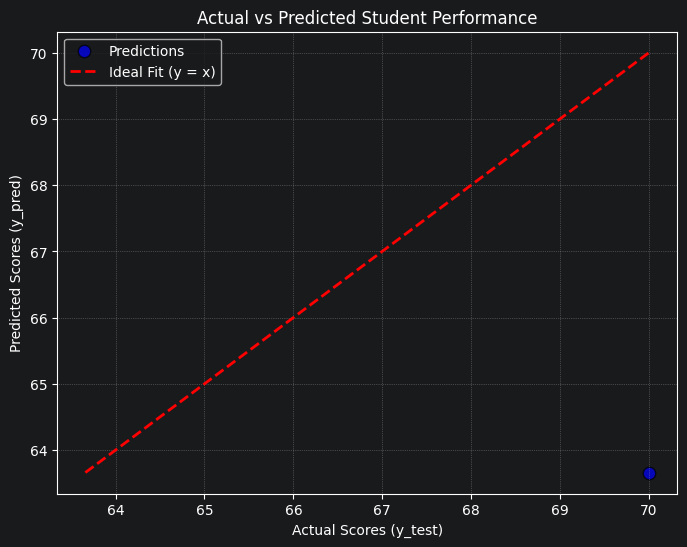

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Split data
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a test model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Plot Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k', s=80, label='Predictions')

min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

plt.xlabel('Actual Scores (y_test)')
plt.ylabel('Predicted Scores (y_pred)')
plt.title('Actual vs Predicted Student Performance')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()